**Process (Roughly):**
1. Get the videos
2. Clean up the dataset
3. Extract keypoints
4. Generate landmark dataset & store it
5. Extract frames & store them
5. Make dataset loaders with both frames & landmarks
6. Train the model
7. Save it in both formats (weights + onnx)



> The WLASL_v0.3.json file contains the glossary and instances of the videos.
> Inside the videos folder, there are about 12k videos each named corresponding video_id.

Needs mediapipe, mlflow and pytorch.


# Imports

In [ ]:
!pip install -q mediapipe mlflow

In [ ]:
import os
import numpy as np
import pandas as pd
from pathlib import Path

from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import json
import time

from typing import Optional,Literal

In [ ]:
import mediapipe as mp
from mediapipe.tasks.python import vision
from mediapipe.tasks.python.core.base_options import BaseOptions
import cv2

In [ ]:
import kagglehub

# Load dataset
DATASET_DIR = "/content/wlasl-processed/"
if not os.path.exists(DATASET_DIR):
  DATASET_DIR = kagglehub.dataset_download("risangbaskoro/wlasl-processed")

print("Data directory: ", DATASET_DIR)

100%|██████████| 4.82G/4.82G [03:52<00:00, 22.3MB/s]

Extracting files...


Data directory:  /root/.cache/kagglehub/datasets/risangbaskoro/wlasl-processed/versions/5


In [ ]:
# Data directories ---
VIDEO_DIR = os.path.join(DATASET_DIR, 'videos')
META_JSON = os.path.join(DATASET_DIR, 'WLASL_v0.3.json')
NSLT_JSON = os.path.join(DATASET_DIR, 'nslt_300.json') # top-k gloss label markdown
CLASSES_TXT = os.path.join(DATASET_DIR, 'wlasl_class_list.txt') # class list
RESULT_DIR = '/content/Results' # where saves will go

In [ ]:
LANDMARK_NPZ = '/content/NSLT_300_landmarks.npz'
FRAME_DATA = '/content/WLASL_FRAMES/'
DEVICE = 'cuda'

BATCH_SIZE = 16
MAX_FRAMES = 32 # For CNN limits
NUM_LANDMARKS = 48

# Data Pre-processing

## Extracting Metadata

Json data organizing - separate each video metadata from the instances, so each video has mandatory fields:

gloss, video_path, split, fps, frame start, frame end

Json -> loaded dataframe -> separate instances -> clean dataframe

In [ ]:
with open(CLASSES_TXT, 'r') as f:
  CLASS_MAP = {
      str_parts[1]: int(str_parts[0])
      for line in f
      if line.strip()
      for str_parts in [line.strip().split()]
      if len(str_parts) >= 2 # format: "0\tclass"
  }

In [ ]:
# metadata json data load as df
# not necessary, just alternative
wlasl_df = pd.read_json(META_JSON)
print("Total instances: ", wlasl_df.shape)
wlasl_df.head()

Total instances:  (2000, 2)


,gloss,instances
0,book,"[{'bbox': [385, 37, 885, 720], 'fps': 25, 'fra..."
1,drink,"[{'bbox': [551, 68, 1350, 1080], 'fps': 25, 'f..."
2,computer,"[{'bbox': [0, 0, 360, 240], 'fps': 25, 'frame_..."
3,before,"[{'bbox': [0, 0, 360, 240], 'fps': 25, 'frame_..."
4,chair,"[{'bbox': [0, 0, 360, 240], 'fps': 25, 'frame_..."


In [ ]:
def extract_json_features(json_data, video_dir):
  """
  Get available video & necessary data only. Makes a cleaned dataframe from the json.
  Input: a json holding video metadata, path to .mp4 direcory.
  Returns: a _features_ pandas dataframe.
  """
  processed_data = []

  for i in tqdm(range(len(json_data)), ncols=100):
      sign = json_data[i]['gloss']
      instances = json_data[i]['instances']

      for instance in instances:
          video_id = instance['video_id']
          video_path = os.path.join(video_dir, f'{video_id}.mp4')
          # check exists
          if not os.path.exists(video_path):
              continue

          frame_start = instance['frame_start']
          frame_end = instance['frame_end']
          split = instance['split']
          signer = instance['signer_id']
          fps = instance['fps']
          bbox = instance['bbox']
          processed_data.append({
              'sign': sign,
              'video_id': video_id,
              'video_path': video_path,
              'split': split,
              'signer_id': signer,
              'fps': fps,
              'frame_start': frame_start,
              'frame_end': frame_end,
              'bbox': bbox
          })

  print("Total instances loaded: ", len(processed_data))
  return processed_data

# metadata json data load
with open(META_JSON, 'r') as file:
  json_data = json.load(file)

wlasl_df = extract_json_features(json_data, VIDEO_DIR)

  0%|                                                                      | 0/2000 [00:00<?, ?it/s]

Total instances loaded:  11980


In [ ]:
# save as a cleaned json
with open('/content/WLASL_v0.3_clean.json', 'w') as json_file:
    json.dump(wlasl_df, json_file, indent=4)

In [ ]:
# or csv just in case
wlasl_df = pd.DataFrame(wlasl_df)
wlasl_df.to_csv('/content/WLASL_v0.3_features.csv', index=False)

Extraction can be done **once**. The results are saved in corresponding .csv and .npz files (metadata, landmarks), and can be loaded.

**Run next cells:**

In [ ]:
import ast
wlasl_df = pd.read_csv('/content/WLASL_v0.3_features.csv', sep=',', converters={"bbox": ast.literal_eval})

In [ ]:
# To pd dataframe
wlasl_df = pd.DataFrame(wlasl_df)
wlasl_df[['video_id', 'sign', 'video_path', 'split']] = wlasl_df[['video_id', 'sign', 'video_path', 'split']].astype(str)
wlasl_df

,sign,video_id,video_path,split,signer_id,fps,frame_start,frame_end,bbox
0,book,69241,/root/.cache/kagglehub/datasets/risangbaskoro/...,train,118,25,1,-1,"[385, 37, 885, 720]"
1,book,07069,/root/.cache/kagglehub/datasets/risangbaskoro/...,train,31,25,1,-1,"[462, 44, 949, 720]"
2,book,07068,/root/.cache/kagglehub/datasets/risangbaskoro/...,train,36,25,1,-1,"[234, 17, 524, 414]"
3,book,07070,/root/.cache/kagglehub/datasets/risangbaskoro/...,train,59,25,1,-1,"[131, 26, 526, 480]"
4,book,07099,/root/.cache/kagglehub/datasets/risangbaskoro/...,val,12,25,1,-1,"[162, 54, 528, 400]"
...,...,...,...,...,...,...,...,...,...
11975,wheelchair,63047,/root/.cache/kagglehub/datasets/risangbaskoro/...,train,11,25,1,-1,"[39, 13, 248, 192]"
11976,wheelchair,63050,/root/.cache/kagglehub/datasets/risangbaskoro/...,train,12,25,1,-1,"[163, 62, 625, 400]"
11977,whistle,63186,/root/.cache/kagglehub/datasets/risangbaskoro/...,train,2,25,1,-1,"[76, 17, 236, 240]"
11978,whistle,63188,/root/.cache/kagglehub/datasets/risangbaskoro/...,train,11,25,1,-1,"[68, 14, 212, 192]"


In [ ]:
wlasl_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11980 entries, 0 to 11979
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   sign         11980 non-null  object
 1   video_id     11980 non-null  object
 2   video_path   11980 non-null  object
 3   split        11980 non-null  object
 4   fps          11980 non-null  int64 
 5   frame_start  11980 non-null  int64 
 6   frame_end    11980 non-null  int64 
 7   bbox         11980 non-null  object
dtypes: int64(3), object(5)
memory usage: 748.9+ KB


In [ ]:
wlasl_df.describe()
print(f"Class quantities:\n{wlasl_df['sign'].value_counts()}")

Class quantities:
sign
before        16
cool          16
thin          16
drink         15
go            15
              ..
grey           2
lamp           2
wash face      2
propaganda     2
post           2
Name: count, Length: 2000, dtype: int64


For some reason, not every class is in the class list, so i'm adding them to the map manually.

In [ ]:
i = max(CLASS_MAP.values()) + 1 if CLASS_MAP else 0
for label in wlasl_df["sign"].unique():
  if label not in CLASS_MAP:
     CLASS_MAP[label] = i
     i += 1

Cropping dataset to top-k signs, depending on the nslt file used:

In [ ]:
# using nslt-100 as test
# json format example:
# "00000": {"subset":"train" "action": [0:90, 1:80, 2:50]}
nslt_df = pd.read_json(NSLT_JSON).T.reset_index().rename(columns = {"index":"video_id"})
wlasl_crop_df = wlasl_df[pd.to_numeric(wlasl_df['video_id']).isin(nslt_df['video_id'])].copy()
print("Total instances: ", wlasl_crop_df.shape)

Total instances:  (2660, 8)


In [ ]:
import shutil
import zipfile
from google.colab import files

def download_video_mp4(df: pd.DataFrame, output_dir: str = "/content/extracted_videos", zip_path: str = "/content/wlasl_100_videos.zip"):
  os.makedirs(output_dir, exist_ok=True)

  # Copy videos
  for _, row in df.iterrows():
      video_id = str(row["video_id"])
      video_path = row["video_path"]

      if not os.path.isfile(video_path):
          print(f"WARNING: File not found: {video_path}")
          continue
      ext = os.path.splitext(video_path)[1]
      destination = os.path.join(output_dir, f"{video_id}{ext}")
      shutil.copy2(video_path, destination)

  print(f"Collected videos in: {output_dir}")

  # Create ZIP
  with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
      for filename in os.listdir(output_dir):
          filepath = os.path.join(output_dir, filename)
          zipf.write(filepath, arcname=filename)

  print(f"Archive created: {zip_path}")
  files.download(zip_path)

download_video_mp4(wlasl_crop_df)

To display of some of the dataset videos:

In [ ]:
wlasl_crop_df.head()

,sign,video_id,video_path,split,fps,frame_start,frame_end,bbox
0,book,69241,/root/.cache/kagglehub/datasets/risangbaskoro/...,train,25,1,-1,"[385, 37, 885, 720]"
1,book,07069,/root/.cache/kagglehub/datasets/risangbaskoro/...,train,25,1,-1,"[462, 44, 949, 720]"
2,book,07068,/root/.cache/kagglehub/datasets/risangbaskoro/...,train,25,1,-1,"[234, 17, 524, 414]"
3,book,07070,/root/.cache/kagglehub/datasets/risangbaskoro/...,train,25,1,-1,"[131, 26, 526, 480]"
4,book,07099,/root/.cache/kagglehub/datasets/risangbaskoro/...,val,25,1,-1,"[162, 54, 528, 400]"


In [ ]:
from IPython.display import HTML
from base64 import b64encode

def display_video(video_path, width=600):
  video_file = open(video_path, "rb").read()
  video_url = f"data:video/mp4;base64,{b64encode(video_file).decode()}"

  # Return HTML video player
  return HTML(f"""
  <video width="{width}" controls>
      <source src="{video_url}" type="video/mp4">
  </video>
  """)

for video_meta in wlasl_crop_df.sample().itertuples():
  print(video_meta.video_path)

/root/.cache/kagglehub/datasets/risangbaskoro/wlasl-processed/versions/5/videos/30831.mp4


In [ ]:
display_video('/root/.cache/kagglehub/datasets/risangbaskoro/wlasl-processed/versions/5/videos/63789.mp4')

Let's test the bounding boxes too, they may be useful later.

65
(55, 0)


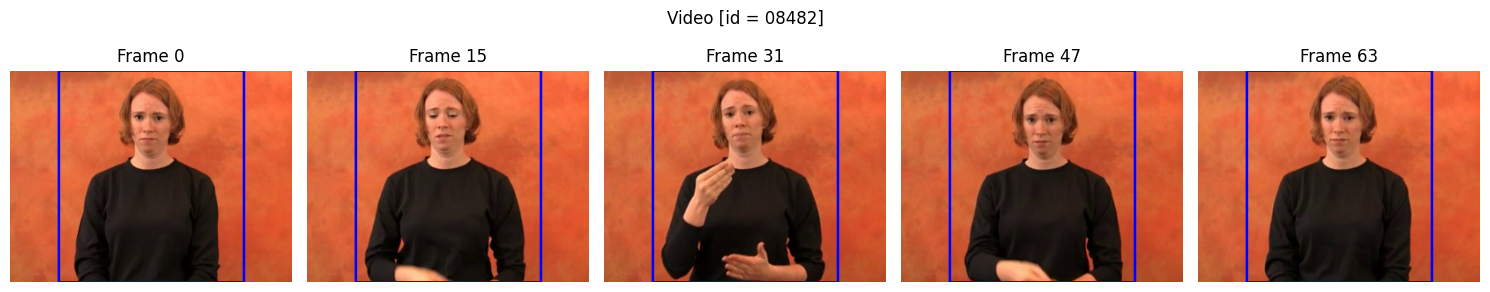

In [ ]:
def test_bbox_frames(video_meta_df: pd.DataFrame, num_frames: int = 5):
  video_meta = video_meta_df.sample().iloc[0]
  video_path = str(video_meta['video_path'])
  bbox = video_meta['bbox']

  cap = cv2.VideoCapture(video_path)
  total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
  print(total_frames)
  print((bbox[0], bbox[1]))
  sampled_frames = np.linspace(0, total_frames - 2, num_frames, dtype=int) # uniform

  fig, axes = plt.subplots(1, num_frames, figsize=(15, 5))
  if num_frames == 1:
    axes = [axes]

  for i, frame_idx in enumerate(sampled_frames):
      cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
      ret, frame = cap.read()
      if not ret:
        axes[i].text(0.5, 0.5, f"ERROR [Frame {frame_idx}]", ha='center', va='center')
      else:
          frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
          cv2.rectangle(frame, (bbox[0], bbox[1]), (bbox[2], bbox[3]), (0, 0, 255), 2)
          # Display
          axes[i].imshow(frame)
          axes[i].set_title(f"Frame {frame_idx}")
      axes[i].axis('off')

  cap.release()
  plt.suptitle(f"Video [id = {video_meta['video_id']}]", y=0.8)
  plt.tight_layout()
  plt.show()

# Random video test
test_bbox_frames(wlasl_crop_df)

## Extracting Mediapipe landmarks

We need only the standard hand landmarks, which start with the wrist and end with the fingertips, and the pose. There are 42 total in mediapipe's hand landmarks, [0-20] and [21-41] (21 total) for each hand.

Landmarks can have:
- video_id [int]
- frame_id [int]
- landmark_id [int]
- x,y,z [float]
+ _confidence [float] - not necessary, for noisy detections_

so **[B, F, T, L, C]**:
- B - batch
- F - frame id
- T - type flag (left, right, pose)
- L - landmark id
- C - coordinates

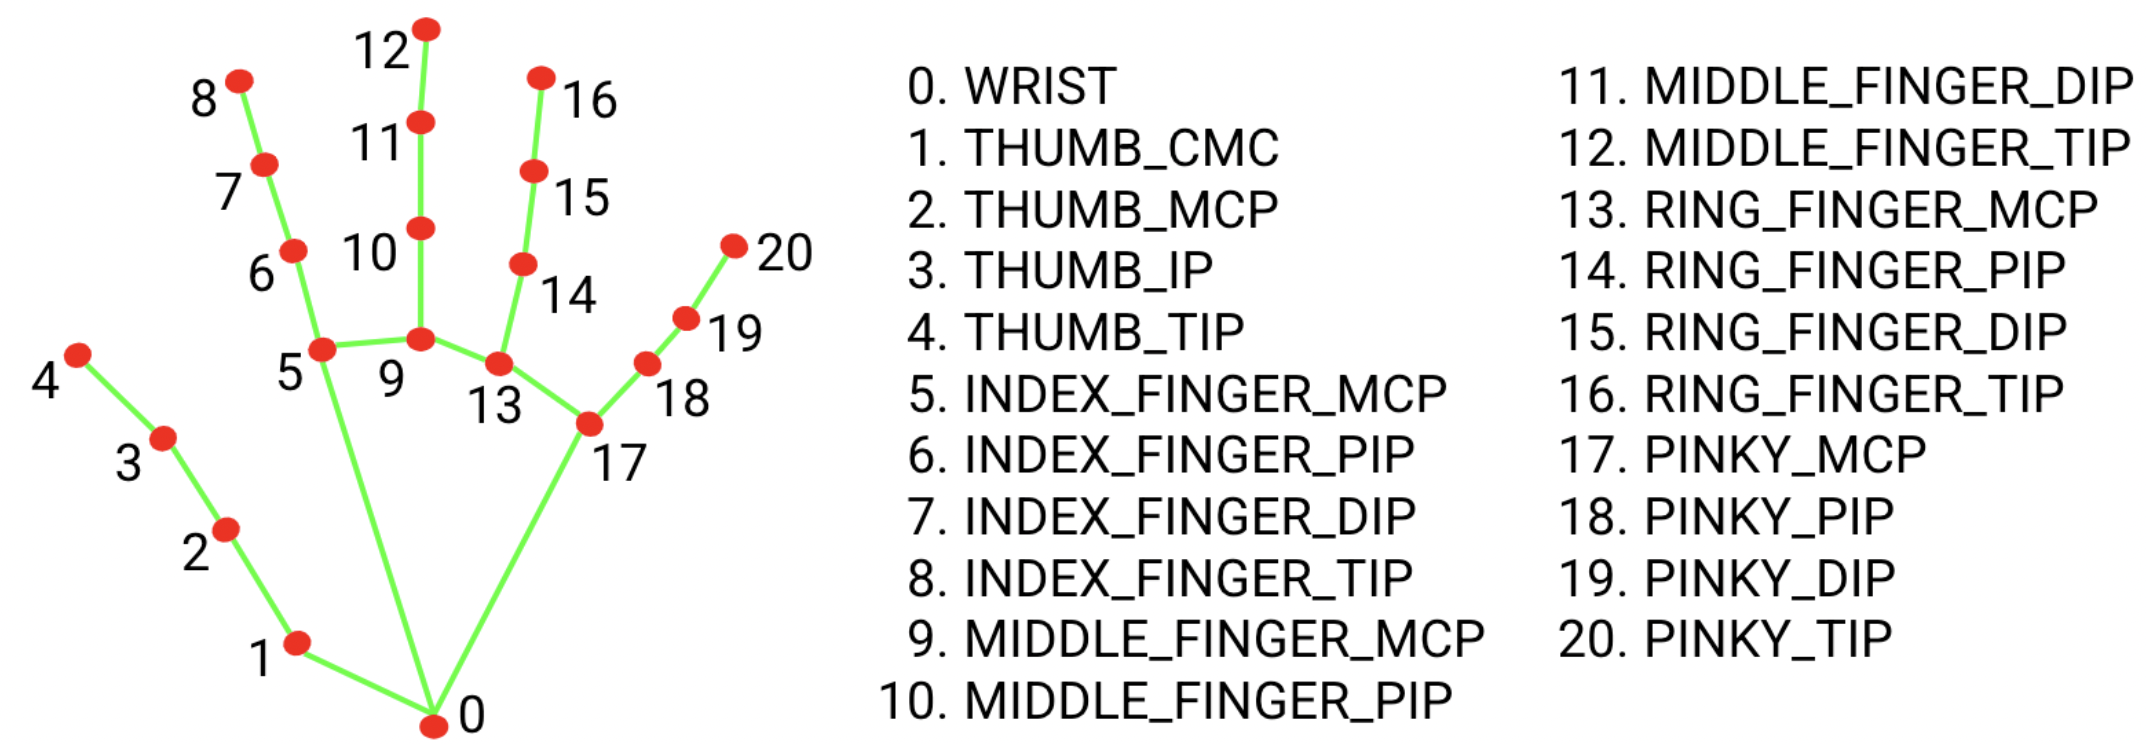

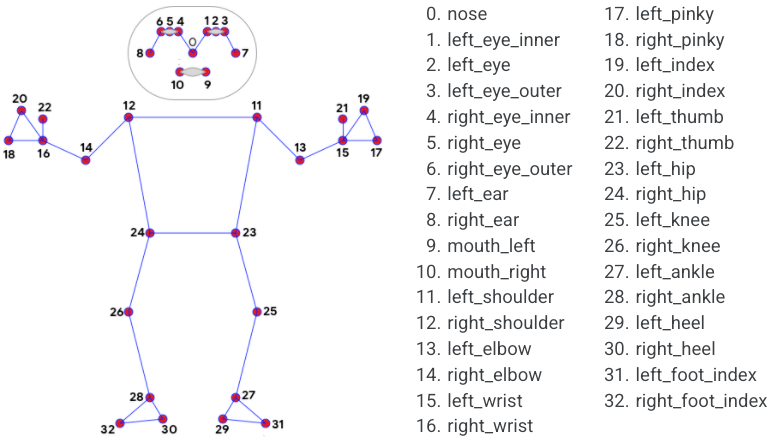

Needs a landmarker model from google apis.

https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/latest/hand_landmarker.task

In [ ]:
# THIS IS A LEGACY SOLUTION. NEW ONE IS THE LANDMARKER.
# mp_hands = mp.solutions.hands.Hands()
# mp_draw_utils = mp.solutions.drawing_utils

### Hands + Pose

In [ ]:
class LandmarkConfig:
  """
  A config class for LandmarkExtractor. Holds values that are not typically changed during landmark detection process.
  """
  HAND_LANDMARKS = list(range(21)) # for both hands 0-21
  POSE_LANDMARKS = [11, 12, 13, 14, 15, 16] # shoulders and arms

  def __init__(self, lm_model_paths: dict, min_detection_confidence: float = 0.5, min_tracking_confidence: float = 0.5, default_detection_mode: Literal["video", "image"] = "video"):
      """
      `lm_model_paths` format example: {"pose": "pose_landmarker.task", "hands": "hand_landmarker.task"}
      """
      if default_detection_mode not in ("video", "image"):
            raise ValueError(f"Detection mode must be either 'video' or 'image': {default_detection_mode}.")
      self.MIN_DETECTION_CONFIDENCE = min_detection_confidence
      self.MIN_TRACKING_CONFIDENCE = min_tracking_confidence # # if fails, detection occurs. better set to lower
      self.MODEL_PATHS = lm_model_paths
      self.default_detection_mode = default_detection_mode
      self.detection_mode = default_detection_mode # CURRENT
      self.NUM_HANDS = 2

  def change_detection_mode(self, detection_mode: Literal["video", "image"] = "video"):
      if detection_mode not in ("video", "image"):
            raise ValueError(f"Detection mode must be either 'video' or 'image': {detection_mode}.")
      self.detection_mode = detection_mode
      print(f'Landmark extraction mode set to "{detection_mode}".')

  def get_landmarker_options(self):
      hand_options = vision.HandLandmarkerOptions(
          base_options = BaseOptions(model_asset_path=self.MODEL_PATHS['hands']),
          running_mode = vision.RunningMode.VIDEO if self.detection_mode == 'video' else vision.RunningMode.IMAGE,
          num_hands = self.NUM_HANDS, # 2 = both
          min_hand_detection_confidence=self.MIN_DETECTION_CONFIDENCE,
          min_tracking_confidence=self.MIN_TRACKING_CONFIDENCE
      )
      pose_options = vision.PoseLandmarkerOptions(
          base_options = BaseOptions(model_asset_path=self.MODEL_PATHS['pose']),
          running_mode = vision.RunningMode.VIDEO if self.detection_mode == 'video' else vision.RunningMode.IMAGE,
          min_pose_detection_confidence=self.MIN_DETECTION_CONFIDENCE,
          min_tracking_confidence=self.MIN_TRACKING_CONFIDENCE
      )
      return {
          "hands": hand_options,
          "pose": pose_options
      }

In [ ]:
class LandmarkExtractor:
  """
  Manages the mediapipe landmark extraction, saving and loading.
  Uses Hand and Pose Landmark solution (locate 33 pose, 21 hand landmarks per hand).
  Utilises a config class 'LandmarkConfig'.
  """
  NUM_COORDS = 3 # x y z dim

  def __init__(self, config: Optional[LandmarkConfig] = None, video_reset_limit: int = 100):
      self.config = config if config is not None else LandmarkConfig()
      self._video_reset_limit = video_reset_limit # detector rebuild
      self._video_count = 0 # since reset
      self._timestamp_ms = 0
      self.pose_detector = None
      self.hand_detector = None
      self._create_detectors()

  def _create_detectors(self):
      """Creates the pose/hand landmark detection models from config options and resets the timestamp clock."""
      self._close_detectors()
      detector_options = self.config.get_landmarker_options()
      self.pose_detector = vision.PoseLandmarker.create_from_options(detector_options['pose'])
      self.hand_detector = vision.HandLandmarker.create_from_options(detector_options['hands'])
      self._timestamp_ms = 0
      self._video_count = 0

  def _close_detectors(self):
      if self.pose_detector is not None:
          self.pose_detector.close()
      if self.hand_detector is not None:
          self.hand_detector.close()
      self.pose_detector = None
      self.hand_detector = None

  def close(self):
      """Closes landmarker models."""
      self._close_detectors()

  # If needed
  @staticmethod
  def sample_frames(frames, max_frames: int, stride: int = 1):
      """
      Skip `frames` data with set `stride`, crop to `max_frames`, shortening extracted video data.
      """
      result = frames[::stride]
      return result[:max_frames]

  @staticmethod
  def normalize_hand(landmarks: np.ndarray):
      """
      Center coordinates around the wrist (index 0), treating it as the origin (0,0,0) in world coordinates.
      Scale landmarks by max distance from origin.
      `landmarks` - (.., 21, 3) coordinates for any HAND.
      Returns: new coordinates with same (.., 21, 3) landmark format.
      """
      wrist = landmarks[:, 0:1, :] # origin landmarks[0]
      centered = landmarks - wrist
      scale = np.linalg.norm(centered, axis=-1) # scale = (.., 21)
      scale = scale.max(axis=-1, keepdims=True) + 1e-6 # landmark with furthest distance in coords. scale = (.., 1)

      return centered / scale[..., None] # broadcast over centered

  @staticmethod
  def crop_frame_bbox(bbox, frame, frame_h: int, frame_w: int, padding: float = 0.10):
      """
      Crop a `frame` to `bbox` bounding range of (x1, y1, x2, y2). The range is extended by `padding` (in percentage, relative to bbox size, per side) to ensure missing no details.
      Returns: cropped frame; bounding region within original frame bounds as [x1, y1, x2, y2].
      """
      x1, y1, x2, y2 = bbox
      bb_w, bb_h = x2 - x1, y2 - y1 # width / height
      cx, cy = (x1 + x2) / 2, (y1 + y2) / 2 # center

      # apply padding
      x1, x2 = cx - int((bb_w / 2) * (1 + padding)), cx + int((bb_w / 2) * (1 + padding))
      y1, y2 = cy - int((bb_h / 2) * (1 + padding)), cy + int((bb_h / 2) * (1 + padding))
      # crop to frame bounds
      x1, y1 = max(0, int(x1)), max(0, int(y1))
      x2, y2 = min(frame_w, int(x2)), min(frame_h, int(y2))

      frame_cropped = frame[y1:y2, x1:x2]
      return frame_cropped, [x1, y1, x2, y2]

  def _landmarker_result_to_arrays(self, hand_result, pose_result):
      """
      Convert landmarker detection result into an array tensor. A utility method used in detection.
      Typical input includes: pose_landmarks, hand_landmarks.
      Returns: landmarks (LANDMARK_N, 3) for each TYPE - pose, left hand, right hand. '0' coordinates means undetected.
      """
      lhand_lm = np.zeros((len(self.config.HAND_LANDMARKS), self.NUM_COORDS), dtype=np.float32)
      rhand_lm = np.zeros((len(self.config.HAND_LANDMARKS), self.NUM_COORDS), dtype=np.float32)
      pose_lm = np.zeros((len(self.config.POSE_LANDMARKS), self.NUM_COORDS), dtype=np.float32)

      # landmarks are filtered by config
      if hand_result.hand_landmarks:
        for handedness, hand_landmarks in zip(hand_result.handedness, hand_result.hand_landmarks): # handedness - left/right
            hand = handedness[0].category_name.lower()
            if hand == 'left':
              lhand_lm = np.array([(lm.x, lm.y, lm.z) for lm in hand_landmarks], dtype=np.float32)[self.config.HAND_LANDMARKS]
            elif hand == 'right':
              rhand_lm = np.array([(lm.x, lm.y, lm.z) for lm in hand_landmarks], dtype=np.float32)[self.config.HAND_LANDMARKS]
      if pose_result.pose_landmarks:
        pose_lm = np.array([(lm.x, lm.y, lm.z) for lm in pose_result.pose_landmarks[0]], dtype=np.float32)[self.config.POSE_LANDMARKS] # pose_landmarks holds multiple poses

      return {
          'pose': pose_lm, 'left_hand': lhand_lm, 'right_hand': rhand_lm
      }

  # HandLandmarker is weird in video mode, for each new video the timestamp is not reset and it throws an error.
  def detect_video_landmarks(self, video_path: str, start_frame: int = 1, end_frame: int = -1, fps: Optional[float] = None, bbox: Optional[tuple] = None):
      """
      Detect landmarks for each frame in a given videofile. Can be given a set `fps`, gloss boundaries [`start_frame`, `end_frame`], and a frame bounding box `bbox` (x1, y1, x2, y2).
      In WLASL `fps` is different from video fps, typically == *25*; `end_frame` == *-1* means until the end.
      Returns: (FRAMES, TYPE_N, LANDMARK_N, 3) detection results for each frame as a list of each 'TYPE' landmark coordinates._
      """
      if self._video_count >= self._video_reset_limit:
        self._create_detectors()

      cap = cv2.VideoCapture(video_path)
      fps = fps or cap.get(cv2.CAP_PROP_FPS)
      total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

      # define start and end frame for detection
      start_frame = max(1, start_frame)
      # start is after the video end
      if start_frame > total_frames:
        start_frame = 1
        end_frame = total_frames
      # until the end handle
      if end_frame < 0 or end_frame > total_frames:
        end_frame = total_frames

      landmarks_pose, landmarks_lhand, landmarks_rhand = [], [], []
      detector_pose_results, detector_hand_results = [], []
      frame_idx = 1 # in video
      detect_frame_idx = 0 # in the [start:end] sequence, just in case
      detector_timestamp = self._timestamp_ms

      # Read video feed
      while cap.isOpened() and frame_idx <= end_frame:
          ret, frame = cap.read()
          if not ret:
            break
          if frame_idx >= start_frame:
              # crop to bbox if given
              if bbox is not None:
                frame, _ = self.crop_frame_bbox(bbox, frame, frame_w=int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), frame_h=int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))

              # BGR to RGB because Mediapipe has no corresponding SBGR
              frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
              mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame)

              # increase ts for video-mode internal tracker
              #timestamp_ms = int(cap.get(cv2.CAP_PROP_POS_MSEC) * 1000)
              timestamp_ms = detector_timestamp + int((detect_frame_idx / fps) * 1000)
              if self.config.detection_mode == "video":
                hand_result = self.hand_detector.detect_for_video(mp_image, timestamp_ms)
                pose_result = self.pose_detector.detect_for_video(mp_image, timestamp_ms)
              else:
                hand_result = self.hand_detector.detect(mp_image)
                pose_result = self.pose_detector.detect(mp_image)

              # add frame landmarks to the output
              landmarks = self._landmarker_result_to_arrays(hand_result, pose_result)
              landmarks_pose.append(landmarks['pose'])
              landmarks_lhand.append(landmarks['left_hand'])
              landmarks_rhand.append(landmarks['right_hand'])
              detector_hand_results.append(hand_result)
              detector_pose_results.append(pose_result)
              detect_frame_idx += 1
              self._timestamp_ms = timestamp_ms + 1

          frame_idx += 1

      cap.release()
      self._video_count += 1
      if detect_frame_idx == 0:
        print('WARNING: no frames were read. Check the video and requested range.')
      return { 'pose': landmarks_pose, 'left_hand': landmarks_lhand, 'right_hand': landmarks_rhand },  { 'pose': detector_pose_results, 'hand': detector_hand_results }

  def detect_for_dataset(self, video_dir: str, video_meta_df: pd.DataFrame, video_path_column: str = 'video_path', sign_column: str = 'sign', normalize: bool = True, save_results: bool = True, save_path: str = '/landmarks/WLASL_landmarks.npz'):
      """
      Detect landmarks for videos specified in a `video_meta_df` dataset. Videos should be available as .mp4 in `video_dir` folder.
      Optionally, save extracted data; normalize hand landmarks, centering coordinates around the wrist.
      Returns: A dictionary of resulting arrays - landmarks, video_ids, sign_labels, frame_index.
      """

      # determine source availabilty
      if video_meta_df is None or video_path_column not in video_meta_df.columns or sign_column not in video_meta_df.columns:
        raise ValueError('No video metadata available - dataframe is unidentified or wrong column specified.')
      if not Path(video_dir).exists():
        raise ValueError('No video files available - `video_dir` path does not exist.')

      landmarks_data = {"pose": [], "left_hand": [], "right_hand": []} # landmarks
      video_ids, sign_labels = [], [] # detected videos and their labels

      for video_data in tqdm(video_meta_df.itertuples(), total=len(video_meta_df), desc="Extracting landmarks"):
          # no check exists, it was cleaned for base dataset
          # using getattr just in case
          video_path = getattr(video_data, video_path_column)
          video_id = getattr(video_data, 'video_id', Path(video_path).stem)
          gloss = getattr(video_data, sign_column, "Unknown")
          fps = getattr(video_data, 'fps', None)
          start_frame = getattr(video_data, 'frame_start', 1)
          end_frame = getattr(video_data, 'frame_end', -1)
          bbox = getattr(video_data, 'bbox', None)

          # extract
          lm, _ = self.detect_video_landmarks(str(video_path), start_frame, end_frame, fps, bbox)
          lm = {k: np.stack(v, axis=0) for k, v in lm.items()} # Make each (F, LANDMARK_N, 3)
          if normalize:
            lm['left_hand'] = self.normalize_hand(lm['left_hand'])
            lm['right_hand'] = self.normalize_hand(lm['right_hand'])

          # append per landmark type
          for lm_key in landmarks_data:
            landmarks_data[lm_key].append(lm[lm_key])
          video_ids.append(video_id)
          sign_labels.append(gloss)

      # constructing video indexing - landmark row from-to ranges per video. 'pose' just because any would fit
      frame_totals = np.array([lm.shape[0] for lm in landmarks_data['pose']]) # frames per video, e.g. 30 30 25...
      frame_ends = np.cumsum(frame_totals) # e.g. 30 60 85...
      frame_starts = frame_ends - frame_totals
      frame_index = np.stack([frame_starts, frame_ends], axis=1)  # (num_videos, 2) indexation table
      # now cut frame ids
      landmarks_data = {k: np.concatenate(v, axis=0) for k, v in landmarks_data.items()}
      video_ids = np.array(video_ids)
      sign_labels = np.array(sign_labels)
      print(f"Landmark extraction completed. Total videos processed: {len(video_ids)}  ({landmarks_data['pose'].shape[0]} frames).")

      if save_results:
        self.save_landmarks(landmarks_data, sign_labels, video_ids, frame_index, output_path=save_path)
      return {
          **landmarks_data, # unpack dict
          'sign_labels': sign_labels,
          'video_ids': video_ids,
          'frame_index': frame_index
      }

  @staticmethod
  def load_landmarks(file_path: str):
      """Loads landmarks from a *.npz* file."""
      with np.load(file_path, allow_pickle=False) as data:
        return {key: data[key] for key in data.files}

  @staticmethod
  def save_landmarks(landmarks, sign_labels: np.ndarray, video_ids: np.ndarray, frame_index: np.ndarray, output_path: str = 'landmarks.npz'):
      """
      Saves landmark data as a *.npz* file, at `output_path` specified.
      `landmarks` - coordinates, a dictionary with per-landmark-type arrays; `sign_labels` - gloss; `video_ids` - extracted videos, `frame_index` - row indexation table for video frames.
      """
      Path(output_path).parent.mkdir(parents=True, exist_ok=True)
      np.savez_compressed(
          output_path,
          pose = landmarks['pose'],
          left_hand = landmarks['left_hand'],
          right_hand = landmarks['right_hand'],
          sign_labels = sign_labels,
          video_ids = video_ids,
          frame_index = frame_index
          )
      print(f"Extracted landmarks saved as '{output_path}'.")

### Testing landmarks

So, let's test it on a random video from the dataset. World landmarks lose the image information so it's just for debugging, most is hardcode:

In [ ]:
from mediapipe.tasks.python.vision import drawing_utils
from mediapipe.tasks.python.vision import drawing_styles

In [ ]:
# LOAD hand_landmarker.task pose_landmarker.task FIRST
# runs in video mode by default, can be changed to image.
landmarker_config = LandmarkConfig({'pose': '/content/pose_landmarker_full.task', 'hands': '/content/hand_landmarker.task'})
landmark_util = LandmarkExtractor(landmarker_config)

In [ ]:
def draw_landmarks_on_frame(frame, detection_result,  landmark_type: Literal["hand", "pose"] = "hand"):
    if landmark_type not in ("hand", "pose"):
      raise ValueError(f"Unknown landmark type: {landmark_type}.")
    if landmark_type == 'hand':
      landmarks_list = detection_result.hand_landmarks
      handedness_list = detection_result.handedness
      landmark_style = drawing_styles.get_default_hand_landmarks_style()
      connection_style = drawing_styles.get_default_hand_connections_style()
      connections = vision.HandLandmarksConnections.HAND_CONNECTIONS
    elif landmark_type == 'pose':
      landmarks_list = detection_result.pose_landmarks
      landmark_style =  drawing_styles.get_default_pose_landmarks_style()
      connection_style = drawing_utils.DrawingSpec(color=(0, 255, 0), thickness=2)
      connections = vision.PoseLandmarksConnections.POSE_LANDMARKS

    annotated_frame = np.copy(frame)

    # Loop through ladnmarks
    for i in range(len(landmarks_list)):
      frame_landmarks = landmarks_list[i]

      # Draw the landmarks
      drawing_utils.draw_landmarks(
        annotated_frame,
        frame_landmarks,
        connections,
        landmark_style,
        connection_style)

    return annotated_frame


def draw_landmarks(landmarks, input_path: str, output_path: str, start_frame: int = 1, end_frame: int = -1, mark_color = (10, 210, 250), ):
    """
    Draw detected landmarks in a video, showing them on top of the visual (for debug). The result is saved in a separate .mp4 file.
    Needs the video itself and its detection results. `landmarks` holds results for both pose and hands solution.
    Use `start_frame` and `end_frame` time marks.
    """
    mp_hands = mp.tasks.vision.HandLandmarksConnections
    mp_pose = mp.tasks.vision.PoseLandmarksConnections
    mp_drawing = mp.tasks.vision.drawing_utils
    mp_drawing_styles = mp.tasks.vision.drawing_styles

    cap = cv2.VideoCapture(input_path)
    fps = cap.get(cv2.CAP_PROP_FPS) or fps
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    frame_w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    frame_h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fourcc = cv2.VideoWriter_fourcc(*'mp4v') # codec
    out = cv2.VideoWriter(output_path, fourcc, fps, (frame_w, frame_h)) # output writer

    # define start and end frame for drawing
    start_frame = max(1, start_frame)
    # start is after the video end
    if start_frame > total_frames:
      start_frame = 1
      end_frame = total_frames
    # until the end handle
    if end_frame < 0:
      end_frame = total_frames

    frame_idx = 1 # in the video
    landmark_idx = 0

    # Read video feed
    while cap.isOpened() and frame_idx <= end_frame:
        ret, frame = cap.read()
        if not ret:
          break

        # write without changes
        if frame_idx < start_frame or frame_idx > end_frame:
          out.write(frame)
          frame_idx += 1
          continue

        # write with drawing
        canvas = draw_landmarks_on_frame(frame, landmarks['pose'][landmark_idx], 'pose')
        canvas = draw_landmarks_on_frame(canvas, landmarks['hand'][landmark_idx], 'hand')
        out.write(canvas)
        frame_idx += 1
        landmark_idx += 1

    cap.release()
    out.release()

In [ ]:
for i, video_meta in wlasl_crop_df.sample(1).iterrows():
  extracted_lm, extracted_res = landmark_util.detect_video_landmarks(video_meta['video_path'], video_meta['frame_start'], video_meta['frame_end'], video_meta['fps'], video_meta['bbox'])
  draw_landmarks(extracted_res, video_meta['video_path'], f'{video_meta['video_id']}_extracted.mp4', video_meta['frame_start'], video_meta['frame_end'], video_meta['fps'])
  #print(f"Extraction result:\n{extracted_lm}")
  #display_video(f'{video_meta['video_id']}_extracted.mp4') # does not work for some reason, works from windows player.

### Landmark Extraction

We need to extract them for the whole dataset, or for a specific nslt (e.g. 100) to use as training data. Can be done once, otherwise use the load method.

In [ ]:
# LOAD hand_landmarker.task pose_landmarker.task FIRST
# runs in video mode by default, can be changed to image.
landmarker_config = LandmarkConfig({'pose': '/content/pose_landmarker_full.task', 'hands': '/content/hand_landmarker.task'})
landmark_util = LandmarkExtractor(landmarker_config)

In [ ]:
# Extract from metadata
landmark_dataset = landmark_util.detect_for_dataset(video_dir=VIDEO_DIR, video_meta_df=wlasl_crop_df, save_path=f'{LANDMARK_DIR}/NSLT_300_landmarks.npz')

In [ ]:
from google.colab import files

files.download(f'{LANDMARK_DIR}/NSLT_300_landmarks.npz')

In [ ]:
landmark_util.close()

### Loading Landmarks

Extraction can be done **once**. The results are saved in corresponding .csv and .npz files (metadata, landmarks), and can be loaded.

**Run next cells:**

In [ ]:
# Load from file
landmark_dataset = LandmarkExtractor.load_landmarks(file_path=LANDMARK_NPZ)

In [ ]:
landmark_dataset['right_hand'][5]

array([[ 0.        ,  0.        ,  0.        ],
       [ 0.22374812, -0.11430883, -0.15984297],
       [ 0.49475235, -0.06308825, -0.22719787],
       [ 0.7091529 ,  0.04830527, -0.26679328],
       [ 0.8677834 ,  0.14981307, -0.29499274],
       [ 0.37138715,  0.20341627, -0.1309455 ],
       [ 0.62813026,  0.29889274, -0.20529288],
       [ 0.80674475,  0.3133394 , -0.26466978],
       [ 0.903615  ,  0.30540293, -0.30033296],
       [ 0.31155103,  0.28602272, -0.0714413 ],
       [ 0.56703657,  0.35838932, -0.11117135],
       [ 0.74395764,  0.35575914, -0.14061555],
       [ 0.85263914,  0.3424065 , -0.16580978],
       [ 0.26197723,  0.3316137 , -0.02951836],
       [ 0.51061815,  0.40235436, -0.08674464],
       [ 0.687815  ,  0.39668876, -0.10555874],
       [ 0.80870885,  0.39097553, -0.11525155],
       [ 0.21931346,  0.354407  ,  0.00106783],
       [ 0.44103593,  0.4175423 , -0.06037369],
       [ 0.5800969 ,  0.42985177, -0.07937145],
       [ 0.6763196 ,  0.43764272, -0.084

## Creating datasets

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
import torchvision.transforms as T

So, we need compiled landmark data in form of torch dataset. The raw extracted format holds more than a preferred tensor (format (B, T, 48, 3) vs (B, T, 144) where 144 = (21+21+6) * 3). For now, the frame data is a variable-length list, so it needs handling later.

This one can be also saved & used as .npz tensor array / .npy files, or a .pickle, but i think the base landmarks are enough.

How to handle batches? For now maybe: pad to the longest clip sequence in the batch, and save a padding mask (for pooling or attention masking). So, each batch has its own T_max - longest in that batch. Shorter clips get zero-padded frames up to T_max.

Also, encode the label data before using. I'll leave video_ids as strings.

In [ ]:
wlasl_crop_df = wlasl_crop_df.rename(columns={'sign': 'sign_name'})
nslt_class_map = {label: i for i, label in enumerate(sorted(wlasl_crop_df["sign_name"].unique()))}
wlasl_crop_df['sign'] = wlasl_crop_df['sign_name'].map(nslt_class_map).astype(int)
wlasl_crop_df.head()

,sign_name,video_id,video_path,split,fps,frame_start,frame_end,bbox,sign
0,book,69241,/kaggle/input/wlasl-processed/videos/69241.mp4,train,25,1,-1,"[385, 37, 885, 720]",33
1,book,07069,/kaggle/input/wlasl-processed/videos/07069.mp4,train,25,1,-1,"[462, 44, 949, 720]",33
2,book,07068,/kaggle/input/wlasl-processed/videos/07068.mp4,train,25,1,-1,"[234, 17, 524, 414]",33
3,book,07070,/kaggle/input/wlasl-processed/videos/07070.mp4,train,25,1,-1,"[131, 26, 526, 480]",33
4,book,07099,/kaggle/input/wlasl-processed/videos/07099.mp4,val,25,1,-1,"[162, 54, 528, 400]",33


In [ ]:
def normalize_video_id(video_id):
    """Returns: video_id in 5-digit string form."""
    if pd.isna(video_id):
        raise ValueError("ERROR: `video_id` cannot be NaN")
    return str(video_id).strip().zfill(5)

### Landmark dataset

In [ ]:
class LandmarkDataset(Dataset):
  """
  A torch dataset made from extracted landmark data - each record holds landmarks for single video's frames.
  """
  def __init__(self, input_path: str, class_map: Optional[dict] = None, video_meta_df: Optional[pd.DataFrame] = None, split: Optional[str] = None, split_column: Optional[str] = 'split'):
      """
      Dataset `input_path` is the .npz result of _process_dataset_. `class_map` has format: _label: index_.
      `video_meta_df` and `split` filter dataset to contain videos from related split, otherwise its the full dataset.
      """
      # load entries
      with np.load(input_path, allow_pickle=False) as data:
        pose = data["pose"] # (FRAMES, POSE_N, 3)
        left_hand = data["left_hand"] # (FRAMES, HAND_N, 3)
        right_hand = data["right_hand"] # (FRAMES, HAND_N, 3)
        self.frame_index = data["frame_index"] # (VIDEO_N, 2) start-end
        self.labels = data["sign_labels"] # (VIDEO_N, )
        self.video_ids = np.array([normalize_video_id(v) for v in data["video_ids"]], dtype=str) # (VIDEO_N, )
      if class_map is None:
          class_map = {c: i for i, c in enumerate(sorted(set(self.labels.tolist())))}
      self.class_map = class_map
      self.landmarks = np.concatenate([pose, left_hand, right_hand], axis=1) # (FRAMES, POSE_N + HAND_N + HAND_N, 3)
      #self.video_ids = [self.video_ids]

      # If a split is specified, slice the arrays down to its data
      if split is not None and video_meta_df is not None:
        #split_entries = set(video_meta_df.loc[video_meta_df[split_column] == split, 'video_id'])
        split_entries = {normalize_video_id(v) for v in video_meta_df.loc[video_meta_df[split_column] == split, "video_id"]}
        #split_mask = np.array([f"{int(v):05d}" in split_entries for v in self.video_ids])
        split_mask = np.array([v in split_entries for v in self.video_ids])
        if not split_mask.any():
          raise ValueError(f"ERROR: No video entries found for split={split} in video metadata.")

        split_video_ids = np.nonzero(split_mask)[0]
        split_landmark_parts = [self.landmarks[s:e] for s, e in self.frame_index[split_video_ids]]
        self.landmarks = np.concatenate(split_landmark_parts, axis=0)
        self.labels = self.labels[split_video_ids]
        self.video_ids = self.video_ids[split_video_ids]

        frame_totals = np.array([s.shape[0] for s in split_landmark_parts])
        new_ends = np.cumsum(frame_totals)
        new_starts = new_ends - frame_totals
        self.frame_index = np.stack([new_starts, new_ends], axis=1)


  def __len__(self):
      return len(self.frame_index)

  def __getitem__(self, idx: int):
    """
    Returns one video's data at `idx` position as a torch tensor.
    Returns data: landmarks, sign_label, video_length.
    """
    start, end = self.frame_index[idx]
    landmarks = self.landmarks[start:end]
    sign_label = self.labels[idx]

    return {
        'landmarks': torch.from_numpy(landmarks).float(),
        'sign_label': torch.tensor(self.class_map[sign_label], dtype=torch.long),
        'video_length': landmarks.shape[0]
    }

In [ ]:
def pad_video_batch(batch: list[dict]):
    """
    Form a padded batch tensor from variable-length videos of the landmark dataset.
    Uses the longest video of the batch to pad other ones to its frame count.
    Returns data: landmarks, hand_presence, sign_labels, padding_mask (1 = padding, 0 = original).
    """
    batch_size = len(batch)
    labels = torch.stack([item['sign_label'] for item in batch])
    lengths = torch.tensor([item['video_length'] for item in batch], dtype=torch.long) # original lengths
    max_frames = int(lengths.max())
    _, num_lm, num_c = batch[0]['landmarks'].shape # (LANDMARK_N, 3)

    # new tensor arrays
    landmarks = torch.zeros(batch_size, max_frames, num_lm, num_c, dtype=torch.float32)
    pad_mask = torch.ones(batch_size, max_frames, dtype=torch.float32)
    # fill them with original data
    for i, item in enumerate(batch):
        frames = item["video_length"]
        landmarks[i, :frames] = item["landmarks"]
        pad_mask[i, :frames] = 0.0

    return {
        'landmarks': landmarks,
        'sign_label': labels,
        'padding_mask': pad_mask
    }

Test:

In [ ]:
train_dataset = LandmarkDataset(f"{LANDMARK_DIR}/NSLT_300_landmarks.npz", CLASS_MAP, wlasl_crop_df, 'train', 'split')

In [ ]:
print(train_dataset.__getitem__(4))

### Frame dataset

If there is a need in raw frame data (e.g. rgb images), then there is a reason to sample them from video. The more frames we get the slower the training will go, but it wont affect it as much in case of landmarks.

In [ ]:
def extract_video_frames(video_path: str, output_dir: str, start_frame: int = 1, end_frame: int = -1, fps: Optional[int] = None):
    """
    Extract frame images to `output_dir` in `video_path` folder. Can use start:end index positions for extraction.
    `end_frame` == -1 means until the end.
    """
    os.makedirs(output_dir, exist_ok=True)
    cap = cv2.VideoCapture(video_path)
    fps = fps or cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    # define start and end frame
    start_frame = max(1, start_frame)
    # start is after the video end
    if start_frame > total_frames:
      start_frame = 1
      end_frame = total_frames
    # until the end handle
    if end_frame < 0 or end_frame > total_frames:
      end_frame = total_frames

    cap.set(cv2.CAP_PROP_POS_FRAMES, start_frame-1)
    frame_idx = start_frame # in video
    relative_frame_idx = 1 # in [start:end)

    # Read video feed
    while cap.isOpened() and frame_idx <= end_frame:
        ret, frame = cap.read()
        if not ret:
          break
        if frame_idx >= start_frame:
          f_path = Path(output_dir) / f'{relative_frame_idx}.jpg'
          cv2.imwrite(f_path, frame)
        frame_idx+=1
        relative_frame_idx+=1
    cap.release()

def extract_frame_data(output_dir: str, video_meta_df: pd.DataFrame, add_path_column: bool = True):
    """
    Extract frame images to `output_dir` for each video in `video_meta_df` in separate video_id folders.
    `add_path_column` - to create a path column of video's frame directory.
    """
    os.makedirs(output_dir, exist_ok=True)
    videos_total = 0

    for row in tqdm(video_meta_df.itertuples(), total=len(video_meta_df), desc="Extracting frames"):
        video_id = normalize_video_id(row.video_id)
        video_out_dir = Path(output_dir) / video_id
        video_path = Path(row.video_path)
        if video_path.exists() == False:
            print(f"Missing video {video_id} in the data folder - skipping..")
        else:
          extract_video_frames(video_path, video_out_dir, row.frame_start, row.frame_end, row.fps)
          videos_total+=1
    print(f"Frame extraction complete for a total of {videos_total} videos.")
    if add_path_column:
        video_meta_df['frames_path'] = video_meta_df["video_id"].apply(lambda v: Path(output_dir) / normalize_video_id(v))

In [ ]:
extract_frame_data(Path(FRAME_DATA), wlasl_crop_df)

Extracting frames:   0%|          | 0/2660 [00:00<?, ?it/s]

Frame extraction complete for a total of 2660 videos.


In [ ]:
class FrameDataset(Dataset):
    """
    A torch dataset made from frame image data - each record holds uniformly sampled frames from a single video.
    """
    FRAME_FILE_EXT = ('.jpg', '.png', '.jpeg')

    def __init__(self, video_meta_df: pd.DataFrame, frame_limit: int = 16, image_size: tuple = (224, 224), split: Optional[str] = None, split_column: Optional[str] = 'split'): #class_map: Optional[dict] = None,
      """
      Dataset `video_meta_df` has columns of video metadata: video_id, video_path, frame_start/end.
      `class_map` has format: _label: index_. `split` filters dataset to contain videos from related split, otherwise its the full dataset.
      Also creates a transform, correspoding to usual CNN expected input.
      """
      # If a split is specified, slice the dataframe down to its data
      if split is not None:
        self.videometa = video_meta_df[video_meta_df[split_column] == split].reset_index(drop=True)
      else:
        self.videometa = video_meta_df
      self.image_size = image_size
      self.frame_limit = frame_limit
      self.transform = T.Compose([
            T.ToPILImage(),
            T.Resize(image_size),
            T.ToTensor(),
            T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]), # ImageNet normalization
        ])
      self.frame_files = {}
      for row in self.videometa.itertuples():
          self.frame_files[row.video_id] = self._locate_frame_files(row.frames_path)

    def __len__(self):
      return len(self.videometa)

    def _locate_frame_files(self, frames_path: str):
      """
      Returns: a sorted list of located frame file paths, sorted by their index number.
      """
      files = [f for f in sorted(os.listdir(frames_path)) if f.lower().endswith(self.FRAME_FILE_EXT)]
      if not files:
          raise ValueError(f'ERROR: frame image directory has no images: {frames_path}')
      files.sort(key=lambda f: int(Path(f).stem))
      return files

    def _sample_frames(self, frames_available: int):
      """
      Sample video data to set `frame_limit` across the `frames_available`, shortening extracted video data.
      Returns: list of frame indexes.
      """
      end_idx = max(frames_available - 1, 0)
      return np.linspace(0, end_idx, num=self.frame_limit, dtype=int)

    def _load_frames(self, meta_row, frame_ids) -> torch.Tensor:
      """
      Loads and transforms frames at given `frame_ids` for a video.
      Returns: (N_FRAMES, 3, H, W)
      """
      frame_paths = self.frame_files[meta_row['video_id']] # e.g. '24.jpg'
      frames = []
      for i in frame_ids:
          f_path = Path(meta_row["frames_path"]) / frame_paths[i]
          frame = cv2.imread(str(f_path))
          if frame is None:
              raise ValueError(f"Failed to read frame image: {f_path}")
          frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
          frames.append(frame)
      return torch.stack([self.transform(f) for f in frames]) # apply transform

    def __getitem__(self, idx: int):
      """
      Returns one video's frames at `idx` position as a torch tensor.
      Returns: frames (N_FRAMES, 3, H, W), video_id.
      """
      meta_row = self.videometa.iloc[idx]
      frame_paths = self.frame_files[meta_row['video_id']] # e.g. '24.jpg'
      frame_ids = self._sample_frames(len(frame_paths))

      return {"frames": self._load_frames(meta_row, frame_ids), "video_id": meta_row["video_id"]}

### Optional augmentation

In [ ]:
import math

class LandmarkAugment:
    """
    Applies noise and other small changes to landmark coordinates for augmentation.
    Operates with (T, V, 3) tensors, expects coordinates.
    """
    def __init__(
        self,
        enabled: bool = True,
        rotation_deg: float = 10.0,
        scale_range: tuple = (0.9, 1.1), # random scale
        random_noise_std: float = 0.01, # gaussian noise
        p: float = 0.5 # chance
        ):
        self.enabled = enabled
        self.rotation = math.radians(rotation_deg)
        self.scale_range = scale_range
        self.random_noise = random_noise_std
        self.p = p

    def __call__(self, landmarks: torch.Tensor) -> torch.Tensor:
        """landmarks: (T, V, 3). Returns: augmented copy."""
        if not self.enabled or torch.rand(1).item() > self.p:
            return landmarks

        landmarks = landmarks.clone()

        # random rotation
        angle = (torch.rand(1).item() * 2 - 1) * self.rotation
        cos_a, sin_a = math.cos(angle), math.sin(angle)
        x, y = landmarks[..., 0].clone(), landmarks[..., 1].clone()
        landmarks[..., 0] = x * cos_a - y * sin_a
        landmarks[..., 1] = x * sin_a + y * cos_a

        # random scale
        scale = torch.empty(1).uniform_(*self.scale_range).item()
        landmarks *= scale

        # gaussian random noise
        landmarks += torch.randn_like(landmarks) * self.random_noise

        return landmarks

### Combined dataset
Landmarks+Frames

In [ ]:
class GestureDataset(Dataset):
    """
    A combined dataset of Landmarks and Frames of each video. Relies on `video_id` lookup to match.
    """
    def __init__(
        self,
        landmark_input_path: str,
        video_meta_df: pd.DataFrame,
        frame_limit: int = 16,
        image_size: tuple = (224, 224),
        class_map: Optional[dict] = None,
        split: Optional[str] = None,
        split_column: Optional[str] = 'split',
        data_length_mode: str = 'fixed', # if frame and landmark data length varies, this should be 'variable'.
        augmentation_util: Optional['LandmarkAugment'] = None # None means disabled, but can be disabled on its own
        ):
        if data_length_mode not in ('fixed', 'variable'):
            raise ValueError(f"Data_length_mode should be 'fixed' or 'variable': {data_length_mode}")
        self.mode = data_length_mode
        self.landmark_data = LandmarkDataset(landmark_input_path, class_map, video_meta_df, split, split_column)
        self.frame_data = FrameDataset(video_meta_df, frame_limit, image_size, split, split_column)
        self._id_lookup = {video_id: idx for idx, video_id in enumerate(self.frame_data.videometa["video_id"].tolist())} # video_id is not real DF index, which getitem() requires
        self.augmentation_util = augmentation_util

    def __len__(self):
        return len(self.landmark_data)

    def __getitem__(self, idx: int):
        """
        Get one video's landmarks and frames at `idx` position as torch tensors.
        Returns: a dict of landmarks (FRAMES, POSE_N + HAND_N + HAND_N, 3), frames (N_FRAMES, 3, H, W), sign_label, video_length.
        """
        landmark_item = self.landmark_data[idx]
        video_id = normalize_video_id(self.landmark_data.video_ids[idx])
        frame_meta_id = self._id_lookup[video_id]
        frame_item = self.frame_data.videometa.iloc[frame_meta_id]
        frame_count = len(self.frame_data.frame_files[frame_item['video_id']])

        if self.mode == 'fixed':
            shared_idx = find_shared_index(landmark_item['landmarks'].shape[0], frame_count, self.frame_data.frame_limit)
            landmarks = landmark_item['landmarks'][shared_idx]
            frames = self.frame_data._load_frames(frame_item, shared_idx)
        else:
            landmarks = landmark_item['landmarks']
            frame_ids = self.frame_data._sample_frames(frame_count)
            frames = self.frame_data._load_frames(frame_item, frame_ids)
        if self.augmentation_util is not None:
            landmarks = self.augmentation_util(landmarks)

        return {
            "landmarks": landmarks,
            "frames": frames,
            "sign_label": landmark_item["sign_label"],
            "video_length": landmarks.shape[0]
        }

In [ ]:
def find_shared_index(landmark_count: int, frame_file_count: int, target_len: int) -> np.ndarray:
    """
    Finds one shared set of `target_len` indices used for landmarks and frame files.
    Returns: (target_len,) array.
    """
    if landmark_count != frame_file_count:
        print(f"WARNING: landmark_count={landmark_count} is different from frame_file_count={frame_file_count}")
    n = min(landmark_count, frame_file_count)
    if n <= 0:
        raise ValueError(f"No usable frames: landmark_count={landmark_count}, frame_file_count={frame_file_count}")
    idx = np.linspace(0, n - 1, num=target_len)
    return np.round(idx).astype(np.int64)

In [ ]:
def collate_variable_batch(batch: list[dict]):
    """
    Forms a single stream of padded variable-length tensors (landmark stream) and fixed-length video-data tensors (frame stream).
    """
    out = pad_video_batch(batch)
    out["frames"] = torch.stack([item["frames"] for item in batch]) # (B, N_FRAMES, C, H, W)
    return out

def collate_fixed_batch(batch: list[dict]):
    """Forms a single stream of equal length tensors."""
    landmarks = torch.stack([b["landmarks"] for b in batch])
    lengths = torch.tensor([b["video_length"] for b in batch])
    t = landmarks.shape[1]
    padding_mask = (torch.arange(t)[None, :] >= lengths[:, None])

    return {
        "landmarks": landmarks,
        "frames": torch.stack([b["frames"] for b in batch]),
        "sign_label": torch.stack([b["sign_label"] for b in batch]),
        "padding_mask": padding_mask.float()
    }

Now create loaders for all splits:

In [ ]:
wlasl_crop_df['split'].unique()

In [ ]:
def create_loaders(
    landmark_data_path: Path | str,
    video_meta_df: pd.DataFrame,
    batch_size: int = BATCH_SIZE,
    frame_limit:int = 16,
    class_map: Optional[dict] = CLASS_MAP,
    collate_fn = torch.utils.data.default_collate,
    augmentation_util: Optional[LandmarkAugment] = None
    ):
    """
    Make dataloaders for train and validation data, based on `dataset_path` .npz file.
    """
    train_dataset = GestureDataset(landmark_data_path, video_meta_df, frame_limit=frame_limit, class_map=class_map, split='train', augmentation_util=augmentation_util)
    val_dataset = GestureDataset(landmark_data_path, video_meta_df, frame_limit=frame_limit, class_map=class_map, split='val')
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, collate_fn=collate_fn, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, collate_fn=collate_fn, shuffle=False)

    return train_loader, val_loader

In [ ]:
train_loader, val_loader = create_loaders(LANDMARK_NPZ, video_meta_df=wlasl_crop_df, frame_limit=32, class_map=nslt_class_map, collate_fn=collate_fixed_batch, augmentation_util=LandmarkAugment())

In [ ]:
test_inputs = next(iter(val_loader))
test_inputs

{'landmarks': tensor([[[[ 0.7211,  0.5188, -0.3323],
           [ 0.2758,  0.5252, -0.3083],
           [ 0.8323,  0.8737, -0.1943],
           ...,
           [ 0.0000,  0.0000,  0.0000],
           [ 0.0000,  0.0000,  0.0000],
           [ 0.0000,  0.0000,  0.0000]],
 
          [[ 0.7210,  0.5184, -0.4656],
           [ 0.2763,  0.5269, -0.5063],
           [ 0.8326,  0.8738, -0.3082],
           ...,
           [ 0.0000,  0.0000,  0.0000],
           [ 0.0000,  0.0000,  0.0000],
           [ 0.0000,  0.0000,  0.0000]],
 
          [[ 0.7211,  0.5182, -0.4605],
           [ 0.2763,  0.5271, -0.4939],
           [ 0.8326,  0.8739, -0.2940],
           ...,
           [ 0.0000,  0.0000,  0.0000],
           [ 0.0000,  0.0000,  0.0000],
           [ 0.0000,  0.0000,  0.0000]],
 
          ...,
 
          [[ 0.7202,  0.5187, -0.4046],
           [ 0.2733,  0.5328, -0.4160],
           [ 0.8291,  0.8749, -0.2486],
           ...,
           [ 0.0000,  0.0000,  0.0000],
           [ 0.00

# Model training

Now we do models. I'll try different architectures to see how they perform.

In [ ]:
import torchvision
import torchvision.transforms as T
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau

## Model Architectures

### Transformer + CNN blocks (main)

This will work in a single stream - CNN extracts features from RGB frames, that are later combined with extracted landmarks to be processed by a transformer block.

In [ ]:
class TransformerCNNBackbone(nn.Module):
  """
  A combined backbone of CNN + Transformer blocks. Utilizes a fine-tuned CNN backbone and attention pooling to process RGB data, attention learning for landmarks.
  Concats per-frame CNN features with landmark features to be encoded by a transformer.
  Backbone starts frozen: Unfreezes AFTER the most training is completed to adjust its weights.
  """
  # Currently uses EfficientNet-B0
  def __init__(
    self,
    num_landmarks: int,
    coord_dim: int = 3,
    cnn_embed_dim: int = 256,
    tf_feedforward_dim: int = 512,
    lm_embed_dim: int = 256,
    combine_dim: int = 256, # feature combination projection
    pretrained: bool = True,
    num_layers: int = 4, # transformer layers
    num_heads: int = 4, # transformer heads
    dropout: float = 0.2,
    max_vid_length: int = 200  # max frames per video
    ):
    super().__init__()
    # CNN partition
    weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
    backbone = torchvision.models.efficientnet_b0(weights=weights)
    backbone_dim = backbone.classifier[1].in_features # 1280 out for Efnet-B0
    self.cnn_features = backbone.features
    self.cnn_pool = nn.AdaptiveAvgPool2d(1)
    self.cnn_projection = nn.Linear(backbone_dim, cnn_embed_dim)
    self.is_backbone_frozen = True
    self.freeze_backbone()

    # Landmark projection & combining
    self.lm_projection = nn.Linear(num_landmarks * coord_dim, lm_embed_dim) # per-frame landmarks
    self.combine_projection = nn.Linear(cnn_embed_dim + lm_embed_dim, combine_dim) # e.g. (in:256+256, out:256)
    self.position_embed = nn.Parameter(torch.randn(1, max_vid_length, combine_dim) * 0.02) # frame index handling

    # Transformer partition
    encoder_layer = nn.TransformerEncoderLayer(
        d_model=combine_dim, nhead=num_heads, dim_feedforward=tf_feedforward_dim,
        dropout=dropout, batch_first=True, activation='gelu', norm_first=True
        )
    self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
    self.norm = nn.LayerNorm(combine_dim)
    # Attention mechanism for weighting frame information of the gesture instead of avg
    # Weight is higher on peak frames, lower on transitional\supportive ones.
    self.attention = nn.Linear(combine_dim, 1)

  def get_param_count(self):
      total = sum(p.numel() for p in self.parameters())
      trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
      frozen = total - trainable

      return {
          "total": total,
          "trainable": trainable,
          "frozen": frozen,
      }

  def freeze_backbone(self, freeze: bool = True, unfreeze_n_blocks: int = 2):
      """Freezes/Unfreezes backbone."""
      for p in self.cnn_features.parameters():
            p.requires_grad = False # Its partial so freeze all first anyway
      if freeze:
          self.cnn_features.eval() # freezes BatchNorm running stats
      else:
          for block in list(self.cnn_features.children())[-unfreeze_n_blocks:]:
            for p in block.parameters():
              p.requires_grad = True
          self.cnn_features.train()
      self.is_backbone_frozen = freeze

  def forward(self, x: torch.Tensor, y: torch.Tensor, padding_mask: torch.Tensor) -> torch.Tensor:
      """
      x: (B, T, V, C) - landmarks;
      y: (B, T, 3, H, W) - rgb frames;
      padding_mask: (B, T) per-batch padding for landmarks (1 = padding, 0 = real).
      Returns: (B, combine_dim)
      """
      b, t, v, c = x.shape # landmarks
      _, _, c_f, h, w = y.shape # frames, b, t are the same
      x = self.lm_projection(x.reshape(b, t, v * c)) # (B, T, lm_embed_dim)
      y = y.reshape(b * t, c_f, h, w)

      if self.is_backbone_frozen:
        with torch.no_grad():
          y = self.cnn_features(y)
      else:
        y = self.cnn_features(y)
      y = self.cnn_pool(y).flatten(1)
      y = self.cnn_projection(y).view(b, t, -1) # (B, T, cnn_embed_dim)

      combined = torch.cat([y, x], dim=-1) # (B, T, cnn+lm)
      combined = self.combine_projection(combined) + self.position_embed[:, :t]

      src_padding_mask = padding_mask.bool()
      features = self.norm(self.encoder(combined, src_key_padding_mask=src_padding_mask))

      attention_scores = self.attention(features).masked_fill(src_padding_mask.unsqueeze(-1), float('-inf'))  # (B, N, 1)
      attention_weights = torch.softmax(attention_scores, dim=1)
      features = (features * attention_weights).sum(dim=1) # (B, combined_dim)

      return features

In [ ]:
class GestureDualModel(nn.Module):
    def __init__(self, num_landmarks, num_classes, combine_dim=256, head_hidden_dim=256, dropout=0.25, backbone_dropout=0.2):
        super().__init__()
        self.backbone = TransformerCNNBackbone(num_landmarks=num_landmarks, combine_dim=combine_dim, dropout=backbone_dropout, num_layers=3)
        self.head = nn.Sequential(
            nn.Linear(combine_dim, head_hidden_dim),
            nn.LayerNorm(head_hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(head_hidden_dim, num_classes)
        )

    def freeze_cnn_backbone(self, freeze: bool = True, unfreeze_n_blocks: int = 2):
        self.backbone.freeze_backbone(freeze, unfreeze_n_blocks)

    def forward(self, landmarks, frames, pad_mask):
        embed = self.backbone(landmarks, frames, pad_mask)
        return self.head(embed)

    def get_param_count(self):
        total = sum(p.numel() for p in self.parameters())
        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        frozen = total - trainable

        return {
            "total": total,
            "trainable": trainable,
            "frozen": frozen,
        }

    def train(self, mode: bool = True):
        super().train(mode)
        if mode and self.backbone.is_backbone_frozen:
            self.backbone.cnn_features.eval()
        return self

### CNN + ST-GCN

This will work in two streams - CNN that processes frame data (RGB), and a spacial temporal graph (ST-GCN) that processes landmarks as a connected skeleton.

In [ ]:
import torchvision
import torchvision.transforms as T

Starting with CNN stream:

In [ ]:
class FrameStreamCNN(nn.Module):
  """
  The CNN part of the combined model. Utilizes a fine-tuned CNN backbone and attention pooling to process RGB data.
  Backbone starts frozen: Unfreezes AFTER the most training is completed to adjust its weights.
  """
  # Currently uses EfficientNet-B0
  def __init__(self, embed_dim: int = 256, dropout: float = 0.2, pretrained: bool = True):
    super().__init__()
    weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
    backbone = torchvision.models.efficientnet_b0(weights=weights)
    backbone_dim = backbone.classifier[1].in_features # 1280 out for Efnet-B0
    self.features = backbone.features
    self.pool = nn.AdaptiveAvgPool2d(1)

    self.projection = nn.Sequential(
        nn.Linear(backbone_dim, embed_dim),
        nn.LayerNorm(embed_dim),
        nn.GELU(),
        nn.Dropout(dropout)
    )

    # Attention mechanism for weighting frame information of the gesture instead of avg
    # Weight is higher on peak frames, lower on transitional\supportive ones.
    self.attention = nn.Linear(embed_dim, 1)
    self.is_backbone_frozen = True
    self.freeze_backbone()

def freeze_backbone(self, freeze: bool = True, unfreeze_n_blocks: int = 2):
    """Freezes/Unfreezes backbone."""
    for p in self.features.parameters():
          p.requires_grad = False # Its partial so freeze all first anyway
    if freeze:
        self.features.eval() # freezes BatchNorm running stats
    else:
        for block in list(self.features.children())[-unfreeze_n_blocks:]:
          for p in block.parameters():
            p.requires_grad = True
        self.features.train()
    self.is_backbone_frozen = freeze

def forward(self, x: torch.Tensor) -> torch.Tensor:
    """ x: (B, N_FRAMES, 3, H, W). Returns: (B, embed_dim)"""
    b, n, c, h, w = x.shape
    x = x.reshape(b * n, c, h, w)

    if self.is_backbone_frozen:
      with torch.no_grad():
        features = self.features(x)
    else:
      features = self.features(x)

    features = self.pool(features).flatten(1) # (B*N, out_dim)
    features = self.projection(features) # (B*N, embed_dim)
    features = features.view(b, n, -1) # (B, N, embed_dim)

    attention_scores = self.attention(features) # (B, N, 1)
    attention_weights = torch.softmax(attention_scores, dim=1)
    features = (features * attention_weights).sum(dim=1) # (B, embed_dim)

    return features

For the skeleton we need an adjacency matrix, and a corresponding aggregation block:

In [ ]:
def build_mediapipe_adjacency(num_landmarks: int, pose_n: int = 6, hand_n: int = 21):
    """
    Builds an adjacency matrix for the concatenated 48 [pose(6) + left(21) + right hand(21)] landmark graph.
    """
    # check landmark count
    # Wrist landmarks are mandatory. If landmark count is changed, this whole method needs to be.
    assert num_landmarks == pose_n + 2 * hand_n, (
        f"Expected {pose_n + 2 * hand_n} landmarks (pose + 2 hands), got {num_landmarks}. "
    )

    # mediapipe pose skeleton and hand skeleton, hardcoded for now
    pose_edges = [
       (0,1), (0,2), (1,3), (2,4), (3,5) # in full = (11, 12), (11, 13), (12, 14), (13, 15), (14, 16)
    ]
    hand_edges = [
        (0, 1), (1, 2), (2, 3), (3, 4),
        (0, 5), (5, 6), (6, 7), (7, 8),
        (5, 9), (9, 10), (10, 11), (11, 12),
        (9, 13), (13, 14), (14, 15), (15, 16),
        (13, 17), (17, 18), (18, 19), (19, 20),
        (0, 17)
    ]
    POSE_LEFT_WRIST, POSE_RIGHT_WRIST = 4, 5 # in full = 15, 16

    edges = list(pose_edges)
    left_offset, right_offset = pose_n, pose_n + hand_n # for listing
    edges += [(a + left_offset, b + left_offset) for a, b in hand_edges]
    edges += [(a + right_offset, b + right_offset) for a, b in hand_edges]

    # connect each hand's wrist (0) to the matching pose wrist
    edges.append((POSE_LEFT_WRIST, left_offset + 0))
    edges.append((POSE_RIGHT_WRIST, right_offset + 0))

    # dense adjacency, symmetrical normalization
    A = torch.eye(num_landmarks)
    for a, b in edges:
      A[a, b] = 1.0
      A[b, a] = 1.0

    deg = A.sum(dim=1)
    deg = deg.pow(-0.5) # inverted sqrt
    deg[torch.isinf(deg)] = 0.0
    deg = torch.diag(deg)
    return deg @ A @ deg # i love maths

In [ ]:
class SpacialFeatureConv(nn.Module):
    """
    Aggregates features of each landmark from its graph neighbours using skeletal adjacency.
    """
    def __init__(self, in_channels: int, out_channels: int, adjacency: torch.Tensor):
        super().__init__()
        self.register_buffer("A", adjacency)
        self.weight = nn.Linear(in_channels, out_channels)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """ x: (B, C, T, V); Returns: (B, C_out, T, V). Aggregates each x features from its neighbors via A(djacency)"""
        x = torch.einsum("vw,bctw->bctv", self.A, x) # < main ST-GCN thingy
        x = x.permute(0, 2, 3, 1) # (B, T, V, C) channels last
        x = self.weight(x)
        return x.permute(0, 3, 1, 2)

class STGCNBlock(nn.Module):
    """
    A single ST-GCN block. Handles spatial graph conv across joints, and temporal conv across frames.
    Utilizes a Conv layer with (`kernel_size`, 1) kernel for temporal features.
    """
    # ?? Make temporal stride 2 in later blocks and adjust padding_mask
    def __init__(self, in_channels: int, out_channels: int, adjacency: torch.Tensor, kernel_size: int = 9, stride:int = 1, dropout: float = 0.1):
        super().__init__()
        self.gcn = SpacialFeatureConv(in_channels, out_channels, adjacency)
        self.bn1 = nn.BatchNorm2d(out_channels)
        pad = (kernel_size - 1) // 2
        self.tcn = nn.Sequential(
            nn.Conv2d(out_channels, out_channels, kernel_size=(kernel_size, 1), padding=(pad, 0), stride=(stride, 1)),
            nn.BatchNorm2d(out_channels),
            nn.Dropout(dropout)
            )
        self.relu = nn.ReLU(inplace=True)
        if in_channels == out_channels and stride == 1:
          self.residual = nn.Identity()
        else:
          self.residual = nn.Sequential(
              nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=(stride, 1)),
              nn.BatchNorm2d(out_channels)
              )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        res = self.residual(x)
        x = self.relu(self.bn1(self.gcn(x)))
        x = self.tcn(x)
        return self.relu(x + res)

In [ ]:
class LandmarkStreamSTGCN(nn.Module):
    """
    The ST-GCN part of a combined model. Utilizes ST-GCN blocks with masked pooling.
    Makes one embedding per video.
    """
    def __init__(
        self,
        num_landmarks: int,
        coord_dim: int = 3,
        embed_dim: int = 256,
        hidden_dims: tuple = (64, 64, 128, 128, 256),
        temporal_kernel: int = 9,
        temporal_stride: tuple = (1, 1, 2, 1, 2), # downsamples T
        dropout: float = 0.2,
        adjacency: torch.Tensor = None
        ):
        super().__init__()
        if adjacency is None:
            adjacency = build_mediapipe_adjacency(num_landmarks)

        self.data_bn = nn.BatchNorm1d(num_landmarks * coord_dim) # for each (landmark, coordinate) channel
        self.temp_strides = temporal_stride

        channels = [coord_dim] + list(hidden_dims)
        self.blocks = nn.ModuleList([
            STGCNBlock(channels[i], channels[i + 1], adjacency, kernel_size=temporal_kernel, dropout=dropout, stride=self.temp_strides[i])
            for i in range(len(hidden_dims))
        ])

        self.projection = nn.Identity() if hidden_dims[-1] == embed_dim else nn.Linear(hidden_dims[-1], embed_dim) # out, leave it as is if its == embed_dim

    def forward(self, landmarks: torch.Tensor, padding_mask: torch.Tensor) -> torch.Tensor:
        """x: (B, T, V, C); Returns: (B, embed_dim)"""
        b, t, v, c = landmarks.shape

        x = landmarks.permute(0, 2, 3, 1).reshape(b, v * c, t) # (B, V*C, T)
        x = self.data_bn(x)
        x = x.reshape(b, v, c, t).permute(0, 2, 3, 1) # (B, C, T, V)

        for block, stride in zip(self.blocks, self.temp_strides):
            x = block(x)
            if stride > 1:
                padding_mask = padding_mask[:, ::stride] # slice mask to match stride
        t = x.shape[2] # x: (B, C_out, T, V); T is changed if stride>1
        padding_mask = padding_mask[:, :t]

        real = (padding_mask == 0).float().view(b, 1, t, 1) # (B,1,T,1), 1 = real frame, no padding
        x = x * real
        real_count = real.sum(dim=2).squeeze(-1).clamp(min=1e-6) # (B,1), for each vid
        pooled = x.sum(dim=(2, 3)) / (real_count * v)

        return self.projection(pooled)  # (B, embed_dim)

And then combine two streams in a new network - this will require a separate training loop as stream input and parameters differ - for example, fine-tuned cnn may need lower LR and needs frames only.

In [ ]:
class GestureGCNCNN(nn.Module):
  """
  A combined model composed from two streams - ST-GCN (landmarks) and a fine-tuned CNN (rgb frames).
  Manages data-to-stream forwarding and backbone freezing, serving as a coordinator.
  """
  def __init__(
      self,
      num_landmarks: int,
      num_classes: int,
      gcn_embed_dim: int = 256, # graph network embed
      cnn_embed_dim: int = 256, # cnn embed
      head_hidden_dim: int = 256, # fusion head dim
      dropout: float = 0.25, # head dropout
      cnn_dropout: float = 0.4,
      stgn_dropout: float = 0.25,
      temp_kernel_size: int = 9,
      adjacency: torch.Tensor = None
      ):
      super().__init__()
      combined_dim = gcn_embed_dim + cnn_embed_dim
      self.landmark_stream = LandmarkStreamSTGCN(num_landmarks=num_landmarks, embed_dim=gcn_embed_dim, adjacency=adjacency, dropout=stgn_dropout, temporal_kernel=temp_kernel_size)
      self.frame_stream = FrameStreamCNN(embed_dim=cnn_embed_dim, dropout=cnn_dropout)
      self.combine_head = nn.Sequential(
          nn.Linear(combined_dim, head_hidden_dim),
          nn.LayerNorm(head_hidden_dim),
          nn.GELU(),
          nn.Dropout(dropout),
          nn.Linear(head_hidden_dim, num_classes)
          )

  def get_param_count(self):
      total = sum(p.numel() for p in self.parameters())
      trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
      frozen = total - trainable

      return {
          "total": total,
          "trainable": trainable,
          "frozen": frozen,
      }

  def freeze_cnn_backbone(self, freeze: bool = True, unfreeze_n_blocks: int = 2):
      self.frame_stream.freeze_backbone(freeze, unfreeze_n_blocks)

  def forward(self, x: torch.Tensor, y: torch.Tensor, pad_mask: torch.Tensor) -> torch.Tensor:
      """
      x: (B, gcn_embed_dim) == landmarks;
      y: (B, cnn_embed_dim) == rgb frames;
      pad_mask: (B, 1) per-batch padding for landmarks.
      Returns: (B, num_classes)
      """
      lm_embed = self.landmark_stream(x, pad_mask)
      frame_embed = self.frame_stream(y)
      combined = torch.cat([lm_embed, frame_embed], dim=1) # concat features
      return self.combine_head(combined)

## Training loop

In [ ]:
import mlflow
from mlflow.models import infer_signature

### Util Definitions

Function to load model checkpoint from given path:

In [ ]:
def save_model(
    model: nn.Module,
    model_name: str,
    save_dir: str = RESULT_DIR,
    config: Optional[dict] = None,
    file_path: Optional[str] = None,
    train_history: Optional[dict] = None,
    epoch: Optional[int] = None
    ) -> str:
    """
    Save a model's state dictionary, config, and training history.
    """
    if file_path is None:
        Path(save_dir).mkdir(parents=True, exist_ok=True)
        file_path = str(Path(save_dir) / f"{model_name}_weights.pt")

    param_counts = (
        model.get_param_count() # type: ignore
        if hasattr(model, "get_param_count")
        else {"total": sum(p.numel() for p in model.parameters())}
    )

    payload = {
        "architecture": model.__class__.__name__,
        "state_dict": model.state_dict(),
        "params": param_counts,
        "epoch": epoch
    }
    if train_history:
        payload["history"] = train_history
    if config:
        payload["config"] = config

    torch.save(payload, file_path)
    print(f"Model {model_name} saved to -> {file_path}")
    return file_path


def load_model(model: nn.Module, path: str, device: str = "cpu") -> tuple[nn.Module, dict]:
    """
    Load weights from save_model() into an EXISTING model.
    Returns (model, payload)
    """
    payload = torch.load(path, map_location=device)
    model.load_state_dict(payload["state_dict"])
    model.to(device)
    architecture = payload.get("architecture", "unknown")
    print(f"Model '{architecture}' loaded from '{path}'")
    return model, payload

def load_checkpoint(path: str, device: str = "cpu") -> tuple[nn.Module, dict]:
    """
    Load weights for resuming training. Rebuilds the model FROM SCRATCH using saved config.
    """
    payload = torch.load(path, map_location=device)
    if "config" not in payload:
        raise ValueError(f"ERROR: Checkpoint {path} has no saved config - rebuild the model manually with load_model() instead.")

    config = payload["config"]
    model = GestureDualModel(
        num_landmarks=config["num_landmarks"],
        num_classes=config["num_classes"],
        combine_dim=config["combine_dim"],
        head_hidden_dim=config["head_hidden_dim"],
        dropout=config["dropout"],
        backbone_dropout=config["backbone_dropout"]
    )
    model.load_state_dict(payload["state_dict"])
    model.to(device)
    return model, config

Custom ES class and optimizer builder for the multi-stream model:

In [ ]:
class EarlyStopping:
    def __init__(self, patience:int =1, min_delta:float = 0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.min_loss = float('inf')

    def early_stop(self, validation_loss: float):
        if validation_loss < self.min_loss - self.min_delta:
            self.min_loss = validation_loss
            self.counter = 0
        elif validation_loss > (self.min_loss + self.min_delta):
            self.counter += 1

        if self.counter >= self.patience:
            return True
        else:
            return False

In [ ]:
# This one for multi-stream
def create_optimizer_mult(model, base_lr = 2e-4, backbone_lr = 1e-5, weight_decay = 1e-4):
    """Separates optimizers for the main network and fine-tuned CNN"""
    backbone_params = list(model.frame_stream.features.parameters())
    backbone_ids = {id(p) for p in backbone_params}
    base_params = [p for p in model.parameters() if id(p) not in backbone_ids]
    return AdamW([
        {'params': [p for p in backbone_params if p.requires_grad], 'lr': backbone_lr},
        {'params': base_params, 'lr': base_lr}
    ], weight_decay=weight_decay)

In [ ]:
# This one for single-stream
def create_optimizer(model, base_lr = 2e-4, backbone_lr = 1e-5, weight_decay = 1e-4):
    """Separates optimizers for the main network and fine-tuned CNN"""
    backbone_params = list(model.backbone.cnn_features.parameters())
    backbone_ids = {id(p) for p in backbone_params}
    base_params = [p for p in model.parameters() if id(p) not in backbone_ids]
    return AdamW([
        {'params': [p for p in backbone_params if p.requires_grad], 'lr': backbone_lr},
        {'params': base_params, 'lr': base_lr}
    ], weight_decay=weight_decay)

Other utils:

In [ ]:
def print_model_params(model, name = 'Customized Model'):
    c = model.get_param_count()
    print(
        f"[{name:<20}] params:"
        f"trainable: {c['trainable']:>10,} | "
        f"frozen: {c['frozen']:>10,} | "
        f"total: {c['total']:>10,}"
    )

def save_history(history, output_dir: str | Path, file_name = 'training_history'):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    history_path = output_dir / f"{file_name}.json"
    with open(history_path, "w") as f:
        json.dump(history, f, indent=2)
    print(f"History saved tp {history_path}")

def load_history(history_path: Optional[str | Path] = None, default_path: str = 'training_history.json'):
    default_hist = {
            "train_loss": [],
            "val_loss": [],
            "train_acc": [],
            "val_acc": [],
            "epoch_time": [],
            "total_time": 0.0
        }
    if history_path is None:
        print(f"Starting new history at {default_path}.")
        return default_hist
    history_path = Path(history_path)
    if not history_path.exists():
        print(f"No history found at given path. Starting new history at {history_path}.")
        return default_hist

    with open(history_path, "r") as f:
        history = json.load(f)
    for key, default_val in default_hist.items():
      history.setdefault(key, default_val)

    print(f"History loaded [{len(history['train_loss'])} epochs] from {history_path}")
    return history


### Training loop (+ MlFlow)

In [ ]:
def run_epoch(
    model: nn.Module,
    loader,
    criterion: nn.Module,
    device: str,
    optimizer: Optional[torch.optim.Optimizer] = None
    ):
    """
    Run 1 training/validation epoch for given `model` over `loader` data.
    Returns metrics: loss, accuracy, performance time.
    """
    is_training = optimizer is not None # if its training loop, optimizer is given
    if is_training:
      model.train()
      grad_ctx = torch.enable_grad()
    else:
      model.eval()
      grad_ctx = torch.no_grad()

    total_loss, total_accuracy, total_samples = 0.0, 0.0, 0
    start_time = time.perf_counter()
    tqdm_bar = tqdm(loader, total=len(loader), desc=f"Processing batches", leave=False, unit="batch")

    with grad_ctx:
      for batch in tqdm_bar:
          landmarks = batch["landmarks"].to(device) # landmark data
          frames = batch["frames"].to(device) # rgb data
          labels = batch["sign_label"].to(device)
          padding_mask = batch["padding_mask"].to(device)

          if is_training:
            optimizer.zero_grad()

          logits = model(landmarks, frames, padding_mask)
          loss = criterion(logits, labels)

          if is_training:
            loss.backward()
            grad_norm = nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0) # clip gradients over the norm, handles exploding grads
            #print("grad norm (pre-clip):", grad_norm.item())
            optimizer.step()

          batch_size = labels.size(0)
          total_loss += loss.item() * batch_size
          total_accuracy += (logits.argmax(dim=1) == labels).float().sum().item()
          total_samples += batch_size

          tqdm_bar.set_postfix(loss=total_loss / total_samples, acc=format(total_accuracy / total_samples, ".2%"))

    return {
        'loss': total_loss / total_samples,
        'accuracy': total_accuracy / total_samples,
        'duration': time.perf_counter() - start_time
        }

Train for N epochs loop:

In [ ]:
from datetime import datetime

def train_model(
        model: nn.Module,
        train_loader,
        val_loader,
        num_epochs: int = 20,
        unfreeze_after: int = 15,
        device: str = 'cpu',
        model_name: str = "Model",
        save_dir: Path | str = "Saved_Models",
        lr: float = 2e-4,
        weight_decay: float = 1e-4,
        es_patience: int = 7,
        checkpoint_step = 10,
        enable_checkpoint: bool = True,
        enable_earlystop: bool = True,
        history_path: Optional[Path | str] = None,
        model_config: Optional[dict] = None
        ):
    """
    Train the model for `num_epochs` epochs and evaluate its performance on validation set.
    Can save checkpoints; unfreeze backbone on `unfreeze_after` epoch; make early stops and save history.
    """

    if not isinstance(save_dir, Path):
        save_dir = Path(save_dir)
    save_dir.mkdir(parents=True, exist_ok=True)
    history = load_history(history_path)

    # Setup MlFlow run
    run = mlflow.start_run(run_name=model_name)
    mlflow.log_params({
        "model_id": model_name,
        "num_epochs": num_epochs,
        "device": device,
        "learning_rate": lr,
        "weight_decay": weight_decay,
        "early_stop_patience": es_patience,
        "batch_size": train_loader.batch_size,
        "n_train_samples": len(train_loader.dataset),
        "n_val_samples": len(val_loader.dataset)
    })

    # Prepare for training
    model = model.to(device)
    model.freeze_cnn_backbone()
    criterion = nn.CrossEntropyLoss(label_smoothing=0.2)
    optimizer = create_optimizer(model, base_lr=lr, weight_decay=weight_decay)
    lr_scheduler = ReduceLROnPlateau(optimizer, factor=0.1, patience=5)
    es = EarlyStopping(patience=es_patience)

    total_start = time.perf_counter()
    starting_epoch = len(history["train_loss"]) # if continued session, this value is the starting epoch.
    total_epoch = starting_epoch + num_epochs # if continued session, this value is the total num_epochs.

    print(f"\n{'='*50}")
    print(f"Training {model_name} for {num_epochs} Epochs.. [{device}]")
    print(f"{'='*50}")

    # Training loop
    for epoch in range(1, num_epochs + 1):
        session_epoch = starting_epoch + epoch
        # Epoch
        train_result = run_epoch(model, train_loader, criterion, device, optimizer)
        val_result = run_epoch(model, val_loader, criterion, device)

        lr_scheduler.step(val_result['loss'])
        epoch_time = train_result['duration'] + val_result['duration']

        history["train_loss"].append(train_result['loss'])
        history["val_loss"].append(val_result['loss'])
        history["train_acc"].append(train_result['accuracy'])
        history["val_acc"].append(val_result['accuracy'])
        history["epoch_time"].append(epoch_time)

        print(
            f"[Epoch {session_epoch:3d}/{total_epoch:3d}] | "
            f"Train loss: {train_result['loss']:.4f}, acc: {format(train_result['accuracy'], "3.4%")} | "
            f"Val loss: {val_result['loss']:.4f}, acc: {format(val_result['accuracy'], "3.4%")}"
        )

        mlflow.log_metrics({
            "train_loss": train_result["loss"],
            "val_loss": val_result["loss"],
            "train_accuracy": train_result["accuracy"],
            "val_accuracy": val_result["accuracy"],
            "learning_rate": lr_scheduler.get_last_lr()[0],
            "epoch_time": epoch_time
        }, step=session_epoch)

        # Check checkpoint
        if session_epoch % checkpoint_step == 0 or epoch == num_epochs:
          checkpoint_path = f'{model_name}_{datetime.now().strftime("%H-%M-%S")}.pt'
          save_model(
            model = model,
            model_name = model_name,
            save_dir = save_dir,
            file_path = checkpoint_path,
            config = model_config,
            epoch = session_epoch
          )
          save_history(history, save_dir, f"{model_name}_{datetime.now().strftime("%H-%M-%S")}_history")
          mlflow.log_artifact(
              checkpoint_path,
              artifact_path="checkpoints"
          )
        # Check early stop
        if es.early_stop(val_result['loss']) and enable_earlystop:
            print(f"Early stopping after {epoch} epoch.. (No improvement for {es_patience} epochs)")
            break
        # Check backbone freezing
        if epoch >= unfreeze_after:
            model.freeze_cnn_backbone(False, unfreeze_n_blocks = 2)
            print(f"Unfreezing backbone blocks after {unfreeze_after} epoch. Starting fine-tuning.")

    total_time = time.perf_counter() - total_start
    history["total_time"] =  (history.get("total_time", 0.0) + total_time)
    mlflow.log_metric("training_time", total_time)

    print(f"\nTraining completed - {total_time / 60:.1f} min, {num_epochs}/{total_epoch} epochs total. | "
        f"Resulting validation acc={history["val_acc"][-1]:.4f}."
    )
    mlflow.set_tag("train_status", "completed")
    mlflow.end_run()
    return history

### Run experiments

In [ ]:
histories = {}

Multi-stream model - CNN + ST-GCN:

In [ ]:
config_dual_gcn = {
    'num_landmarks': NUM_LANDMARKS,
    'num_classes': len(nslt_class_map),
    'gcn_embed_dim': 256,
    'cnn_embed_dim': 256,
    'head_hidden_dim': 256,
    'dropout': 0.3,
    'cnn_dropout': 0.4,
    'stgn_dropout': 0.25,
    'temp_kernel_size': 9
}

In [ ]:
model_dual_gcn = GestureGCNCNN(
    num_landmarks=config_dual_gcn['num_landmarks'],
    num_classes=config_dual_gcn['num_classes'],
    gcn_embed_dim=config_dual_gcn['gcn_embed_dim'],
    cnn_embed_dim=config_dual_gcn['cnn_embed_dim'],
    head_hidden_dim=config_dual_gcn['head_hidden_dim'],
    dropout=config_dual_gcn['dropout'],
    cnn_dropout=config_dual_gcn['cnn_dropout'],
    stgn_dropout=config_dual_gcn['stgn_dropout'],
    temp_kernel_size=config_dual_gcn['temp_kernel_size']
)
print_model_params(model_dual_gcn)

[Customized Model    ] params:trainable:  1,604,365 | frozen:  4,007,548 | total:  5,611,913


In [ ]:
print(model_dual_gcn)

GestureGCNCNN(
  (landmark_stream): LandmarkStreamSTGCN(
    (data_bn): BatchNorm1d(144, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (blocks): ModuleList(
      (0): STGCNBlock(
        (gcn): SpacialFeatureConv(
          (weight): Linear(in_features=3, out_features=64, bias=True)
        )
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (tcn): Sequential(
          (0): Conv2d(64, 64, kernel_size=(9, 1), stride=(1, 1), padding=(4, 0))
          (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): Dropout(p=0.25, inplace=False)
        )
        (relu): ReLU(inplace=True)
        (residual): Sequential(
          (0): Conv2d(3, 64, kernel_size=(1, 1), stride=(1, 1))
          (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        )
      )
      (1): STGCNBlock(
        (gcn): SpacialFeatureConv(
          (weight): Linear(

Single-stream model - CNN + Transformer:

In [ ]:
config_dual_tf = {
    'num_landmarks': NUM_LANDMARKS,
    'num_classes': len(nslt_class_map),
    'combine_dim': 256,
    'head_hidden_dim': 256,
    'dropout': 0.25,
    'backbone_dropout': 0.4
}

In [ ]:
model_dual_tf = GestureDualModel(
    num_landmarks=config_dual_tf['num_landmarks'],
    num_classes=config_dual_tf['num_classes'],
    combine_dim=config_dual_tf['combine_dim'],
    head_hidden_dim=config_dual_tf['head_hidden_dim'],
    dropout=config_dual_tf['dropout'],
    backbone_dropout=config_dual_tf['backbone_dropout']
)
print_model_params(model_dual_tf)

In [ ]:
print(model_dual_tf)

GestureDualModel(
  (backbone): TransformerCNNBackbone(
    (cnn_features): Sequential(
      (0): Conv2dNormActivation(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): SiLU(inplace=True)
      )
      (1): Sequential(
        (0): MBConv(
          (block): Sequential(
            (0): Conv2dNormActivation(
              (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
              (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
              (2): SiLU(inplace=True)
            )
            (1): SqueezeExcitation(
              (avgpool): AdaptiveAvgPool2d(output_size=1)
              (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
              (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
              (activation): SiLU(inplace=True)
  

In [ ]:
model_dual_tf, config_dual_tf = load_checkpoint(Path(RESULT_DIR) / 'Saved_Experiments' / 'TransformerCNN_weights.pt', DEVICE)
load_history(Path(RESULT_DIR) / 'Saved_Experiments' /'TransformerCNN_history.json')

In [ ]:
print(f'>> Starting training phase..')
histories['TransformerCNN'] = train_model(
    model = model_dual_tf,
    train_loader = train_loader,
    val_loader = val_loader,
    device = DEVICE,
    save_dir = Path(RESULT_DIR) / "Saved_Experiments",
    model_name = 'TransformerCNN',
    num_epochs = 10,
    unfreeze_after=5,
    checkpoint_step = 5,
    model_config = config_dual_tf,
    history_path = Path(RESULT_DIR) / 'Saved_Experiments' /'TransformerCNN_16-55-39_history.json'
)

>> Starting training phase..
History loaded [20 epochs] from /content/drive/My Drive/Навчання/Diploma/Saved_Experiments/Saved_Experiments/TransformerCNN_16-55-39_history.json

Training TransformerCNN for 10 Epochs.. [cuda]


Processing batches:   0%|          | 0/238 [00:00<?, ?batch/s]

Processing batches:   0%|          | 0/56 [00:00<?, ?batch/s]

[Epoch  21/ 30] | Train loss: 2.4436, acc: 86.3996% | Val loss: 3.7915, acc: 33.6323%


Processing batches:   0%|          | 0/238 [00:00<?, ?batch/s]

Processing batches:   0%|          | 0/56 [00:00<?, ?batch/s]

... (21 outputs left out)

[Epoch  29/ 30] | Train loss: 2.3028, acc: 88.4555% | Val loss: 3.7395, acc: 36.3229%
Unfreezing backbone blocks after 5 epoch. Starting fine-tuning.


Processing batches:   0%|          | 0/238 [00:00<?, ?batch/s]

Processing batches:   0%|          | 0/56 [00:00<?, ?batch/s]

[Epoch  30/ 30] | Train loss: 2.2707, acc: 89.7733% | Val loss: 3.7244, acc: 35.8744%
Model TransformerCNN saved to -> TransformerCNN_21-02-52.pt
History saved tp /content/drive/My Drive/Навчання/Diploma/Saved_Experiments/Saved_Experiments/TransformerCNN_21-02-52_history.json
Unfreezing backbone blocks after 5 epoch. Starting fine-tuning.

Training completed - 123.2 min, 10/30 epochs total. | Resulting validation acc=0.3587.


### Export

In [ ]:
!pip install onnx onnxruntime onnxscript

In [ ]:
import onnx
import onnxruntime as ort

def export_to_onnx(
    model: nn.Module,
    output_path: str,
    num_landmarks: int,
    frame_limit: int,
    image_size: tuple = (224, 224),
    opset_version: int = 18
    ):
    """
    Exports a trained dual model to ONNX.
    """
    model.eval()
    device = next(model.parameters()).device

    # dummy inputs for export
    dummy_landmarks = torch.randn(1, frame_limit, num_landmarks, 3, device=device)
    dummy_frames = torch.randn(1, frame_limit, 3, *image_size, device=device)
    dummy_pad_mask = torch.zeros(1, frame_limit, dtype=torch.bool, device=device)

    with torch.no_grad():
        torch.onnx.export(
            model,
            (dummy_landmarks, dummy_frames, dummy_pad_mask),
            output_path,
            input_names=["landmarks", "frames", "padding_mask"],
            output_names=["output"], # logits
            dynamic_axes={
                "landmarks": {0: "batch_size"},
                "frames": {0: "batch_size"},
                "padding_mask": {0: "batch_size"},
                "output": {0: "batch_size"}
            },
            opset_version=18
        )
    print(f"Model exported as ONNX to: {output_path}")
    return output_path

def verify_onnx(model: nn.Module, onnx_path: str, num_landmarks: int, frame_limit: int, image_size=(224, 224), atol=1e-4):
    model.eval()
    dummy_landmarks = torch.randn(2, frame_limit, num_landmarks, 3)
    dummy_frames = torch.randn(2, frame_limit, 3, *image_size)
    dummy_pad_mask = torch.zeros(2, frame_limit, dtype=torch.bool)

    with torch.no_grad():
        torch_out = model(dummy_landmarks, dummy_frames, dummy_pad_mask).numpy()

    session = ort.InferenceSession(onnx_path)
    onnx_out = session.run(None, {
        "landmarks": dummy_landmarks.numpy(),
        "frames": dummy_frames.numpy(),
        "padding_mask": dummy_pad_mask.numpy(),
    })[0]

    max_diff = np.abs(torch_out - onnx_out).max()
    status = "OK" if max_diff < atol else "MISMATCH"
    print(f"{status}: Max output difference == {max_diff:.6f} (tolerance: {atol})")
    return max_diff < atol

In [ ]:
model_dual_tf.to("cpu")
onnx_export_path = Path(RESULT_DIR) / "Saved_Experiments"  / f"TransformerCNN_{datetime.now().strftime("%H-%M-%S")}.onnx"
export_to_onnx(model_dual_tf, onnx_export_path, NUM_LANDMARKS, MAX_FRAMES)